![Logo SENATI](../00_Recursos/logo_senati.png)

**SENATI · Laboratorio práctico de IA y visión computacional**  
**Instructor:** Ing. Gunar Castro Iñigo  
**Tecnologías:** Python · OpenCV · NumPy · Matplotlib  
**Modalidad:** demostración → ejecución → interpretación → reto

# Módulo 1 · Importancia de la visión computacional en IA

**Propósito:** Explicar cómo las máquinas extraen información de imágenes y diferenciar imagen, procesamiento y decisión.

**Actividad completada por:** COCA CCORPA LORENA ABIGAIL.  
**Fuente:** SEMANA 12 TALLER · SENATI.  
Se conservó el nombre original de este cuaderno. Las imágenes son las suministradas por el taller o transformaciones documentadas de ellas.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Todos los cuadernos se ejecutan desde su propia carpeta.
RECURSOS = Path('..') / '00_Recursos'
SALIDAS = Path('resultados')
SALIDAS.mkdir(exist_ok=True)

def mostrar(imagen, titulo='Resultado', gris=False):
    """Muestra imágenes en Jupyter sin abrir ventanas externas."""
    plt.figure(figsize=(8, 4))
    if gris:
        plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
    plt.show()

print('Entorno listo. OpenCV:', cv2.__version__)

Entorno listo. OpenCV: 4.13.0


## Explicación

Cuando vemos un semáforo, primero **observamos colores y formas**, luego **interpretamos** lo que significan y finalmente **decidimos** qué hacer. Un sistema de visión computacional intenta reproducir partes de ese flujo utilizando imágenes y algoritmos.

**Visión computacional:** campo de la IA que busca extraer información útil de imágenes y video. No toda operación sobre imágenes es IA aprendida: una regla de color puede funcionar sin entrenamiento.

**Flujo práctico:** imagen → lectura de píxeles → procesamiento → identificación → respuesta.

### Demostración 1: ¿qué información contiene una imagen?

Ancho: 720 píxeles | Alto: 420 píxeles | Canales: 3


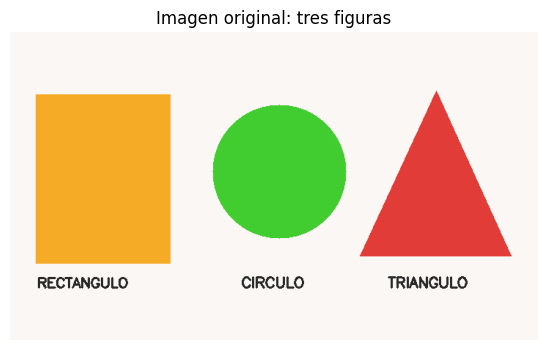

In [2]:
ruta = RECURSOS / 'figuras.png'
imagen = cv2.imread(str(ruta))
assert imagen is not None, 'No se pudo leer la imagen; revisa la carpeta 00_Recursos.'
alto, ancho, canales = imagen.shape
print(f'Ancho: {ancho} píxeles | Alto: {alto} píxeles | Canales: {canales}')
mostrar(imagen, 'Imagen original: tres figuras')

**Interpretación:** la computadora no recibe “un círculo” como concepto. Recibe números organizados por filas, columnas y canales. El reconocimiento necesita reglas o un modelo.

### Demostración 2: tomar una decisión mediante una regla simple

In [3]:
# Medimos el color del píxel dentro del círculo verde.
b, g, r = map(int, imagen[190, 367])
print('BGR leído:', (b, g, r))
if g > r and g > b:
    print('Decisión: en ese punto predomina el VERDE.')
else:
    print('Decisión: el verde no es dominante.')

BGR leído: (47, 204, 65)
Decisión: en ese punto predomina el VERDE.


### Aplicaciones 

- Industria: detectar piezas defectuosas en una banda transportadora.
- Seguridad vial: interpretar señales y marcas de tránsito.
- Agricultura: estimar áreas dañadas en las hojas.
- Salud: asistir en el análisis de imágenes médicas, siempre con validación profesional.

**Reto:** modifica las coordenadas para leer el rectángulo. ¿Qué canal predomina? <br>
**Pregunta oral:** ¿por qué leer un color no equivale a reconocer un objeto completo?

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza el reto y sus comprobaciones. Se conserva el enunciado original y el código se ejecuta en orden.</div>

### Respuestas cortas

**¿Qué canal predomina?** El verde: promedio BGR del rectángulo [47, 204, 65].  
**¿Por qué leer un color no reconoce un objeto?** Un solo píxel no describe forma ni contexto.

## Ejecución del reto del estudiante (actividad resuelta)

Promedio del rectángulo [B,G,R]: [ 47. 204.  65.]
Canal dominante en esta zona: VERDE


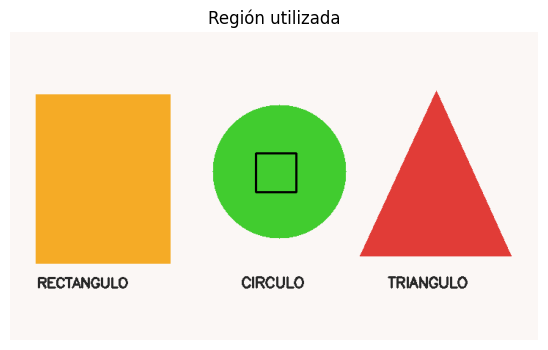

In [4]:
# Reto: medir una zona rectangular en lugar del punto aislado.
# Dato original es una imagen didáctica del taller, no cámara real.
x1,y1,x2,y2=335,165,390,218
zona = imagen[y1:y2,x1:x2]
promedio_bgr = zona.mean(axis=(0,1))
print('Promedio del rectángulo [B,G,R]:',promedio_bgr.round(2))
canal = ['AZUL','VERDE','ROJO'][int(promedio_bgr.argmax())]
print('Canal dominante en esta zona:',canal)
annotada=imagen.copy()
cv2.rectangle(annotada,(x1,y1),(x2,y2),(0,0,0),2)
cv2.imwrite(str(SALIDAS/'01_zona_analizada.png'),annotada)
mostrar(annotada,'Región utilizada')

### Conclusión y evaluación

La media de una región suaviza variaciones de píxeles individuales. La posición debe ajustarse al objeto; no es una detección automática.

**Evidencia:** ejecutar todas las celdas; las imágenes guardadas en `resultados/` muestran el procesamiento. La captura del cuaderno abierto corresponde al estudiante una vez ejecutado en su máquina.